# Diagnóstico inicial del fraude

**Pregunta:** ¿las transacciones poco habituales son también fraudulentas?

Este notebook complementa al original del taller y deja un diagnóstico reproducible:
datos, partición por patrones repetidos, señales univariantes y evaluación de un GMM fijo.
No hay búsqueda de hiperparámetros. El resultado es una validación interna exploratoria:
el conjunto de construcción ya se examinó en el estudio previo y no constituye un test
independiente. Producción se utiliza para comprobar el esquema; no interviene en el ajuste.

**Objetivo del taller:** ordenar operaciones con un score continuo, mayor = más sospechoso,
y evaluar con `average_precision_score` (AP). AP no es la integración trapezoidal de la curva PR.
El score de anomalía no es una probabilidad calibrada de fraude.

**Ejecución:** abrir este archivo con `javi/` como directorio de trabajo y ejecutar las celdas
en orden. Ambos ZIP originales deben permanecer en la raíz del repositorio, un nivel por encima. Las dependencias están en `estudio_datos/diagnostico_inicial/requirements.txt`.
Los gráficos quedan visibles aquí; tablas, scores de validación y figuras se guardan también
en `estudio_datos/diagnostico_inicial/`. No se descargan datos ni se modifica el notebook original.

In [1]:
%matplotlib inline
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

SEMILLA = 42
PREDICTORES = [f"X{i}" for i in range(1, 21)] + ["Amount"]
RAIZ = Path.cwd().resolve()
DATOS = RAIZ.parent
assert (RAIZ / "estudio_datos").is_dir(), "Ejecutar desde javi/."
SALIDA = RAIZ / "estudio_datos" / "diagnostico_inicial"
FIGURAS = SALIDA / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
COLORES = {0: "#176b87", 1: "#c65a16"}

def guardar_figura(fig, nombre):
    """Guarda la misma figura que se muestra en el notebook."""
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

versiones = {p: version(p) for p in ["pandas", "numpy", "scipy", "scikit-learn", "matplotlib",
                                   "nbformat", "nbclient", "ipykernel", "threadpoolctl"]}
display(pd.Series({"Python": platform.python_version(), **versiones}, name="Versión"))

Python           3.12.14
pandas             2.2.3
numpy              2.5.4
scipy             1.18.1
scikit-learn       1.9.1
matplotlib        3.11.2
nbformat          5.11.1
nbclient          0.11.0
ipykernel          7.4.0
threadpoolctl      3.7.0
Name: Versión, dtype: object

## 1. Qué datos tenemos

`Class=0` identifica operaciones normales y `Class=1`, fraude. `Class` nunca entra como predictor.
No disponemos de fecha, cliente ni significado documentado para X1…X20. El índice conserva
la posición en el CSV; no representa tiempo. La coincidencia de variables no demuestra que
dos filas sean la misma transacción.

In [2]:
rutas = {"construccion": DATOS / "credit_card_construction.csv.zip",
         "produccion": DATOS / "credit_card_production.csv.zip"}
for ruta in rutas.values():
    assert ruta.is_file(), f"Falta el archivo local {ruta.name}"
construccion = pd.read_csv(rutas["construccion"])
produccion = pd.read_csv(rutas["produccion"])
for nombre, df in [("construccion", construccion), ("produccion", produccion)]:
    assert list(df.columns) == PREDICTORES + ["Class"], f"Esquema inesperado: {nombre}"
    assert np.isfinite(df[PREDICTORES].to_numpy()).all(), f"Nulos o infinitos: {nombre}"
assert construccion["Class"].notna().all()
assert set(construccion["Class"].unique()) == {0, 1}
assert produccion["Class"].isna().all(), "Producción contiene etiquetas; revisar el protocolo."
X = construccion[PREDICTORES]
y = construccion["Class"].astype(int)
resumen_datos = pd.DataFrame([
    {"conjunto": nombre, "filas": len(df), "predictores": len(PREDICTORES),
     "nulos_predictores": int(df[PREDICTORES].isna().sum().sum()),
     "etiquetas_disponibles": int(df["Class"].notna().sum()),
     "patrones_repetidos_adicionales": int(df.duplicated(PREDICTORES).sum())}
    for nombre, df in [("construcción", construccion), ("producción", produccion)]
]).set_index("conjunto")
display(resumen_datos)
display(pd.DataFrame({"operaciones": y.value_counts().sort_index(),
                      "porcentaje": 100 * y.value_counts(normalize=True).sort_index()})
        .rename(index={0: "Normal", 1: "Fraude"}))
display(Markdown(f"Un clasificador que siempre devuelve normal tendría **{100*(1-y.mean()):.3f}% de accuracy**. "
                 f"El score constante tiene **AP={y.mean():.6f}** en construcción."))

,filas,predictores,nulos_predictores,etiquetas_disponibles,patrones_repetidos_adicionales
conjunto,,,,,
construcción,170884,21,0,170884,4167
producción,113923,21,0,0,2109


,operaciones,porcentaje
Class,,
Normal,170589,99.827368
Fraude,295,0.172632


Un clasificador que siempre devuelve normal tendría **99.827% de accuracy**. El score constante tiene **AP=0.001726** en construcción.

## 2. Validación sin patrones repetidos entre particiones

Creamos grupos mediante igualdad exacta de las 21 variables, sin usar `Class` para agrupar.
Con diez folds estratificados por grupos y semilla 42, reservamos los folds 0, 1 y 2 como
validación. Se fijan antes de entrenar, sin elegirlos por rendimiento: aproximadamente 70/30.
El agrupamiento permite estudiar patrones nuevos y es una sensibilidad útil ante las
repeticiones observadas; no sustituye una separación por cliente o fecha si estos datos aparecen.

Las descripciones por clase y la selección univariante posteriores usan únicamente train.
Esta partición interna no borra la exploración global realizada antes de crear el notebook.

In [3]:
grupos = X.groupby(PREDICTORES, dropna=False, sort=False).ngroup().to_numpy()
contradicciones = pd.DataFrame({"grupo": grupos, "Class": y}).groupby("grupo")["Class"].nunique()
print("Patrones con etiquetas contradictorias:", int((contradicciones > 1).sum()))
partidor = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
folds = list(partidor.split(np.zeros((len(X), 1)), y, groups=grupos))
idx_validacion = np.sort(np.concatenate([folds[i][1] for i in (0, 1, 2)]))
idx_train = np.setdiff1d(np.arange(len(X)), idx_validacion, assume_unique=True)
assert np.intersect1d(grupos[idx_train], grupos[idx_validacion]).size == 0
assert np.intersect1d(idx_train, idx_validacion).size == 0
assert len(idx_train) + len(idx_validacion) == len(X)
X_train, X_validacion = X.iloc[idx_train].copy(), X.iloc[idx_validacion].copy()
y_train, y_validacion = y.iloc[idx_train].copy(), y.iloc[idx_validacion].copy()
normales_train = y_train.eq(0)
resumen_split = pd.DataFrame([
    {"conjunto": nombre, "filas": len(idx), "fraudes": int(y.iloc[idx].sum()),
     "prevalencia": float(y.iloc[idx].mean()), "grupos": int(np.unique(grupos[idx]).size)}
    for nombre, idx in [("entrenamiento", idx_train), ("validación", idx_validacion)]
]).set_index("conjunto")
display(resumen_split)

# Solo diagnosticamos el split original; no entrenamos otro modelo ni elegimos entre splits.
original_train, original_valid = train_test_split(np.arange(len(X)), test_size=.3,
                                                stratify=y, random_state=SEMILLA)
solape_original = int(np.isin(grupos[original_valid], grupos[original_train]).sum())
print(f"Filas de validación con patrón presente en train: original={solape_original}; agrupado=0")

Patrones con etiquetas contradictorias: 0


,filas,fraudes,prevalencia,grupos
conjunto,,,,
entrenamiento,119617,205,0.001714,116701
validación,51267,90,0.001756,50016


Filas de validación con patrón presente en train: original=1643; agrupado=0


## 3. Señales descriptivas en entrenamiento

Comparamos medianas y AP de cada variable en ambas direcciones. Elegimos variable y signo
con la AP de train; los empates se resuelven por orden de columnas y dirección +1 antes de −1.
Esta elección usa etiquetas y constituye una referencia supervisada sencilla. Su AP de train
es optimista por selección: la comparación útil se hará después en validación.

In [4]:
filas_senales = []
candidatos = []
for columna in PREDICTORES:
    valores = X_train[columna].to_numpy()
    ap_alta = average_precision_score(y_train, valores)
    ap_baja = average_precision_score(y_train, -valores)
    candidatos.extend([(columna, 1, float(ap_alta)), (columna, -1, float(ap_baja))])
    filas_senales.append({"variable": columna,
        "mediana_normal": X_train.loc[normales_train, columna].median(),
        "mediana_fraude": X_train.loc[~normales_train, columna].median(),
        "AP_valor_alto_train": ap_alta, "AP_valor_bajo_train": ap_baja,
        "mejor_AP_train": max(ap_alta, ap_baja),
        "direccion": "alto" if ap_alta >= ap_baja else "bajo"})
senales = pd.DataFrame(filas_senales).sort_values("mejor_AP_train", ascending=False, kind="stable")
variable_elegida, signo_elegido, ap_univariante_train = max(candidatos, key=lambda v: v[2])
display(senales.reset_index(drop=True))
print(f"Regla fijada en train: score = {signo_elegido:+d} × {variable_elegida}")

,variable,mediana_normal,mediana_fraude,AP_valor_alto_train,AP_valor_bajo_train,mejor_AP_train,direccion
0,X17,-12.000000,"-1,134.000000",0.003309,0.623415,0.623415,bajo
1,X14,10.000000,"-1,356.000000",0.000904,0.612366,0.612366,bajo
2,X12,28.000000,"-1,062.000000",0.000878,0.565505,0.565505,bajo
3,X10,-18.000000,-964.000000,0.000917,0.548104,0.548104,bajo
4,X11,-8.000000,730.000000,0.505207,0.000892,0.505207,alto
5,X16,14.000000,-702.000000,0.001082,0.471557,0.471557,bajo
6,X18,0.000000,-364.000000,0.001895,0.328022,0.328022,bajo
7,X9,-10.000000,-406.000000,0.000960,0.321068,0.321068,bajo
8,X3,36.000000,-990.000000,0.000891,0.225689,0.225689,bajo
9,X4,-6.000000,778.000000,0.194203,0.000879,0.194203,alto


Regla fijada en train: score = -1 × X17


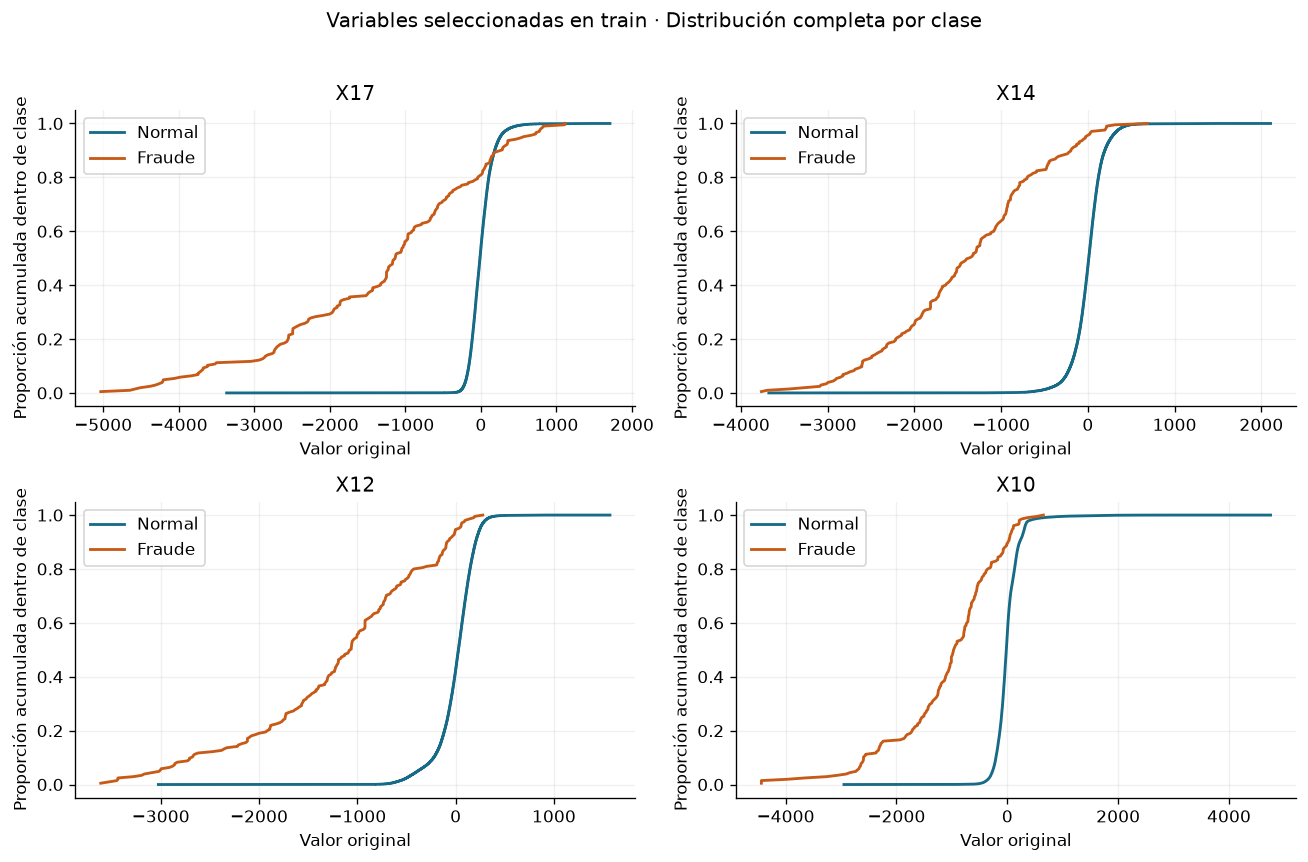

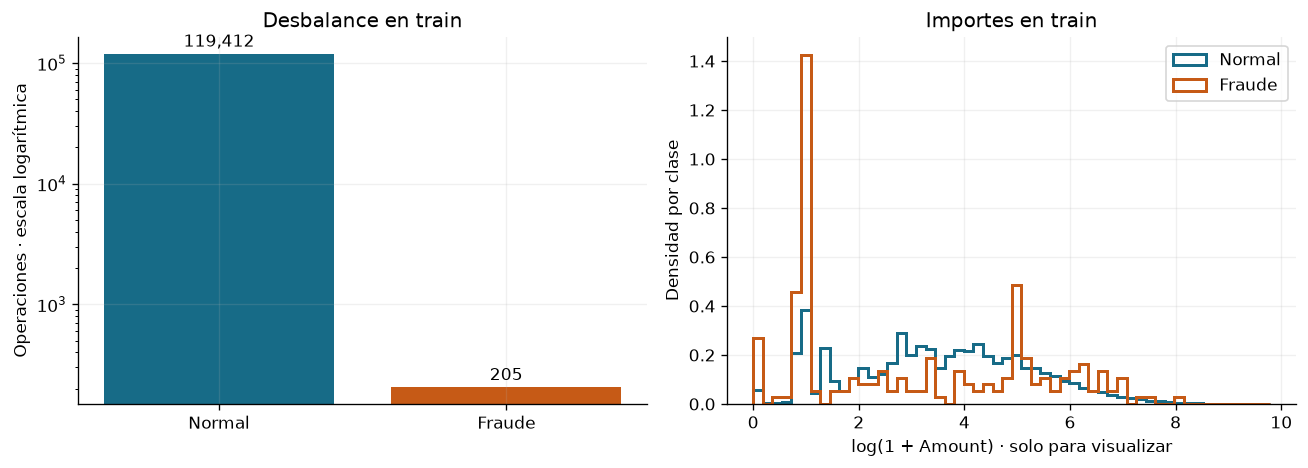

In [5]:
variables_grafico = senales.head(4)["variable"].tolist()
fig, ejes = plt.subplots(2, 2, figsize=(11, 7))
for eje, columna in zip(ejes.flat, variables_grafico):
    for clase, etiqueta in [(0, "Normal"), (1, "Fraude")]:
        valores = np.sort(X_train.loc[y_train.eq(clase), columna].to_numpy())
        eje.plot(valores, np.arange(1, len(valores)+1)/len(valores),
                 label=etiqueta, color=COLORES[clase], linewidth=1.7)
    eje.set(title=columna, xlabel="Valor original", ylabel="Proporción acumulada dentro de clase")
    eje.legend()
fig.suptitle("Variables seleccionadas en train · Distribución completa por clase", y=1.02)
guardar_figura(fig, "01_distribuciones_train")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
conteos = y_train.value_counts().sort_index()
ejes[0].bar(["Normal", "Fraude"], conteos, color=[COLORES[0], COLORES[1]])
ejes[0].set(yscale="log", ylabel="Operaciones · escala logarítmica", title="Desbalance en train")
for i, n in enumerate(conteos): ejes[0].text(i, n*1.15, f"{n:,}", ha="center")
assert (X_train["Amount"] >= 0).all()
limites = np.linspace(0, np.log1p(X_train["Amount"]).max(), 55)
for clase, etiqueta in [(0, "Normal"), (1, "Fraude")]:
    ejes[1].hist(np.log1p(X_train.loc[y_train.eq(clase), "Amount"]), bins=limites,
                 density=True, histtype="step", linewidth=1.8, label=etiqueta, color=COLORES[clase])
ejes[1].set(xlabel="log(1 + Amount) · solo para visualizar", ylabel="Densidad por clase", title="Importes en train")
ejes[1].legend()
guardar_figura(fig, "02_clases_importes")

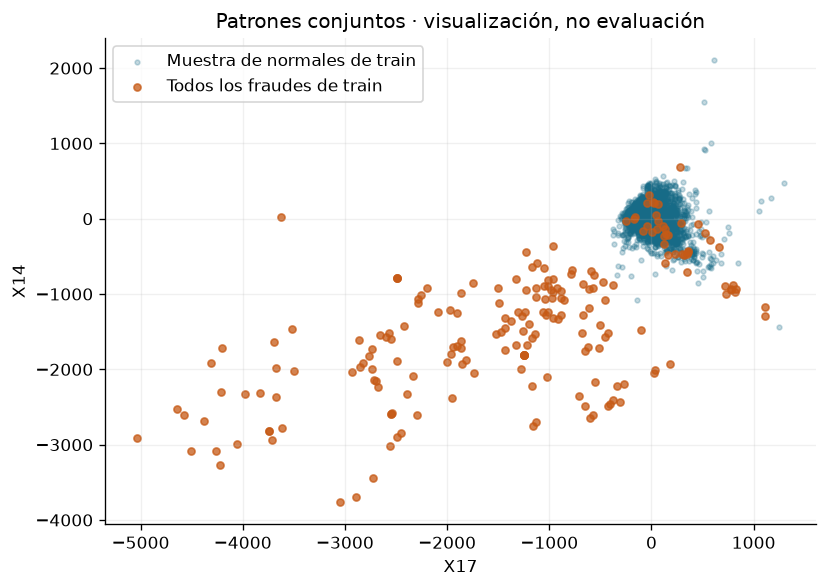

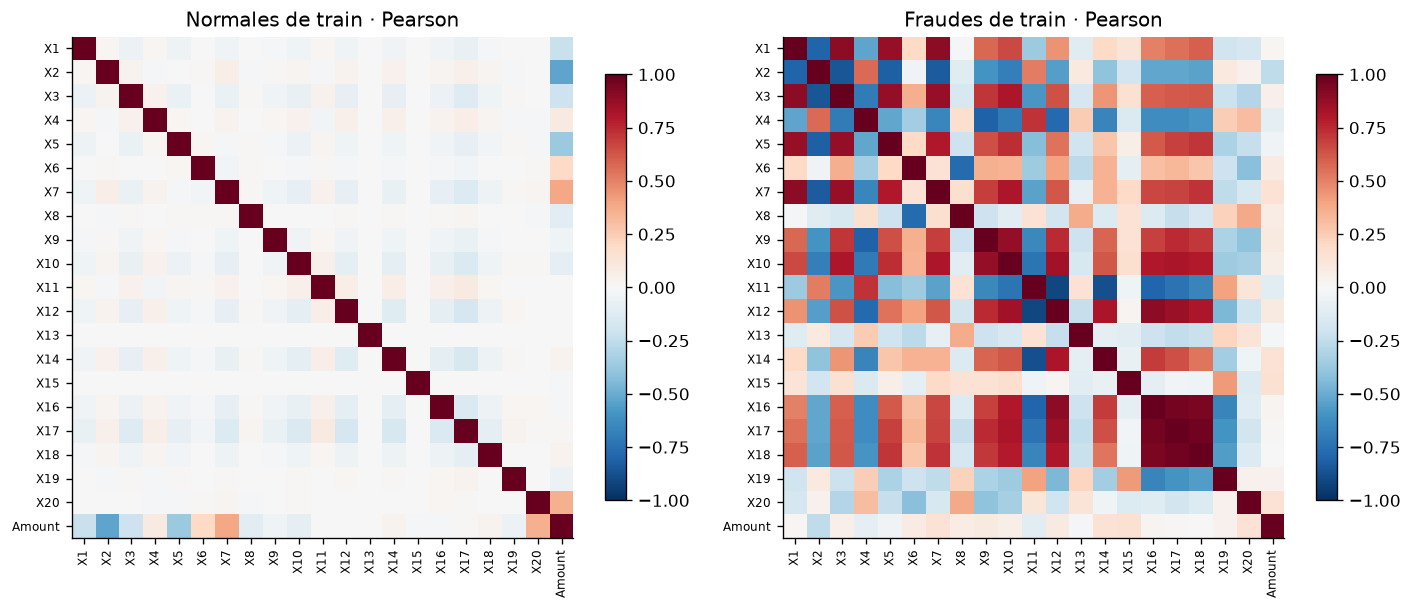

In [6]:
columnas_scatter = variables_grafico[:2]
muestra_normales = X_train.loc[normales_train].sample(n=min(4000, int(normales_train.sum())), random_state=SEMILLA)
fig, eje = plt.subplots(figsize=(7, 5))
eje.scatter(muestra_normales[columnas_scatter[0]], muestra_normales[columnas_scatter[1]],
            s=8, alpha=.25, color=COLORES[0], label="Muestra de normales de train")
eje.scatter(X_train.loc[~normales_train, columnas_scatter[0]], X_train.loc[~normales_train, columnas_scatter[1]],
            s=18, alpha=.75, color=COLORES[1], label="Todos los fraudes de train")
eje.set(xlabel=columnas_scatter[0], ylabel=columnas_scatter[1], title="Patrones conjuntos · visualización, no evaluación")
eje.legend()
guardar_figura(fig, "03_patrones_train")

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for eje, clase, etiqueta in zip(ejes, [0, 1], ["Normales", "Fraudes"]):
    correlacion = X_train.loc[y_train.eq(clase)].corr()
    imagen = eje.imshow(correlacion, vmin=-1, vmax=1, cmap="RdBu_r")
    eje.grid(False)
    eje.set_xticks(range(len(PREDICTORES)), PREDICTORES, rotation=90, fontsize=7)
    eje.set_yticks(range(len(PREDICTORES)), PREDICTORES, fontsize=7)
    eje.set_title(f"{etiqueta} de train · Pearson")
    fig.colorbar(imagen, ax=eje, shrink=.8)
guardar_figura(fig, "04_correlaciones_train")

## 4. GMM de referencia: aprender normalidad

Fijamos cinco componentes, covarianza completa, una inicialización y semilla 42, siguiendo
el punto de partida del taller. Como adaptación explícita, escalamos con media y desviación
de los **normales de train**; el GMM se ajusta únicamente a esas mismas observaciones.
No se ajustan componentes ni transformaciones a la AP de validación.

Filtrar `Class=0` utiliza etiquetas para identificar normalidad: este régimen no es
completamente no supervisado. La baja densidad puede identificar operaciones legítimas raras.
Al usar una transformación afín fija, la corrección de densidad al espacio original es una
constante común a las filas y no cambia el ranking.

In [7]:
escalador = StandardScaler()
X_normales_escalados = escalador.fit_transform(X_train.loc[normales_train])
X_train_escalado = escalador.transform(X_train)
X_validacion_escalado = escalador.transform(X_validacion)
parametros_gmm = dict(n_components=5, covariance_type="full", n_init=1,
                      random_state=SEMILLA, reg_covar=1e-6, tol=1e-3, max_iter=200)
gmm = GaussianMixture(**parametros_gmm)
inicio = time.perf_counter()
with warnings.catch_warnings(record=True) as avisos_gmm:
    warnings.simplefilter("always")
    with threadpool_limits(limits=2):
        gmm.fit(X_normales_escalados)
        score_gmm_train = -gmm.score_samples(X_train_escalado)
        score_gmm_validacion = -gmm.score_samples(X_validacion_escalado)
segundos_gmm = time.perf_counter() - inicio
assert gmm.converged_, "GMM sin convergencia: no interpretar sus métricas; revisar el ajuste."
assert np.isfinite(score_gmm_train).all() and np.isfinite(score_gmm_validacion).all()
min_autovalor = float(np.linalg.eigvalsh(gmm.covariances_).min())
assert min_autovalor > 0
diagnostico_ajuste = {"normales_utilizados": int(normales_train.sum()),
    "convergencia": bool(gmm.converged_), "iteraciones": int(gmm.n_iter_),
    "min_autovalor_covarianza": min_autovalor,
    "segundos_ajuste_y_scores": segundos_gmm,
    "avisos": [str(a.message) for a in avisos_gmm]}
display(pd.Series(diagnostico_ajuste, name="Diagnóstico del ajuste"))

normales_utilizados          119412
convergencia                   True
iteraciones                      39
min_autovalor_covarianza   0.000003
segundos_ajuste_y_scores   2.183645
avisos                           []
Name: Diagnóstico del ajuste, dtype: object

## 5. ¿El score ordena los fraudes por delante?

Comparamos el score constante, la regla univariante elegida con etiquetas de train y el GMM
ajustado con normales de train. La AP de entrenamiento del GMM tampoco es generalización:
los normales ya participaron en su ajuste. El score constante obtiene exactamente la prevalencia
de cada partición. Los tres procedimientos se evalúan sobre las mismas filas de validación.

,AP_train,AP_validacion,AP_sobre_prevalencia
modelo,,,
Constante,0.001714,0.001756,1.000000
Regla univariante,0.623415,0.669823,381.553708
GMM 5 componentes,0.689538,0.747130,425.590108


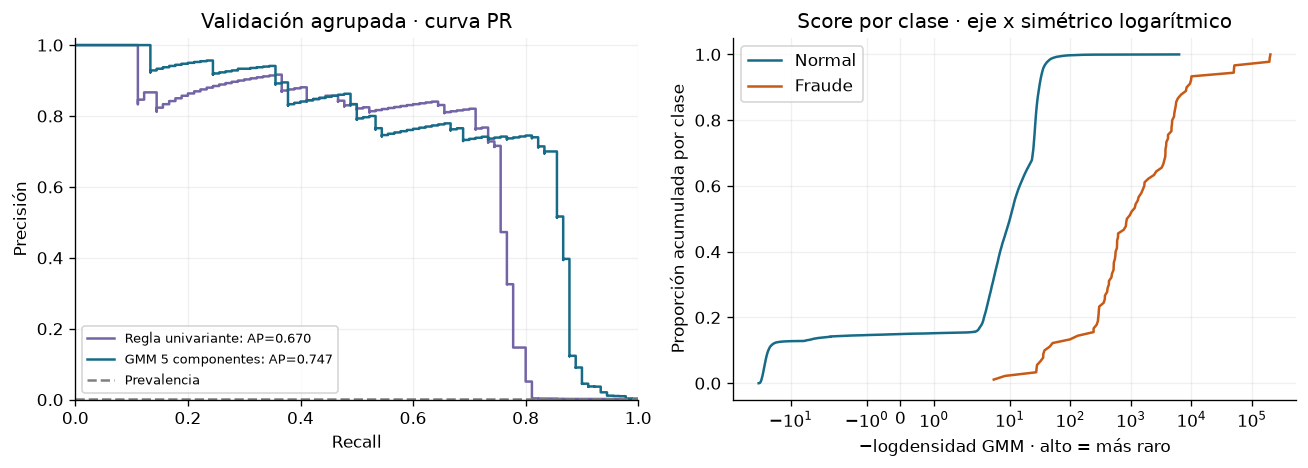

In [8]:
scores_train = {"Constante": np.zeros(len(X_train)),
                "Regla univariante": signo_elegido * X_train[variable_elegida].to_numpy(),
                "GMM 5 componentes": score_gmm_train}
scores_validacion = {"Constante": np.zeros(len(X_validacion)),
                     "Regla univariante": signo_elegido * X_validacion[variable_elegida].to_numpy(),
                     "GMM 5 componentes": score_gmm_validacion}
metricas = pd.DataFrame([
    {"modelo": nombre, "AP_train": average_precision_score(y_train, scores_train[nombre]),
     "AP_validacion": average_precision_score(y_validacion, scores),
     "AP_sobre_prevalencia": average_precision_score(y_validacion, scores) / y_validacion.mean()}
    for nombre, scores in scores_validacion.items()
]).set_index("modelo")
assert np.isclose(metricas.loc["Constante", "AP_validacion"], y_validacion.mean())
display(metricas)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, color in [("Regla univariante", "#7364a5"), ("GMM 5 componentes", "#176b87")]:
    precision, recall, _ = precision_recall_curve(y_validacion, scores_validacion[nombre])
    ejes[0].step(recall, precision, where="post", color=color,
                 label=f"{nombre}: AP={metricas.loc[nombre, 'AP_validacion']:.3f}")
ejes[0].axhline(y_validacion.mean(), color="gray", linestyle="--", label="Prevalencia")
ejes[0].set(xlabel="Recall", ylabel="Precisión", title="Validación agrupada · curva PR", xlim=(0, 1), ylim=(0, 1.02))
ejes[0].legend(fontsize=8)
for clase, etiqueta in [(0, "Normal"), (1, "Fraude")]:
    valores = np.sort(score_gmm_validacion[y_validacion.to_numpy() == clase])
    ejes[1].plot(valores, np.arange(1, len(valores)+1)/len(valores), color=COLORES[clase], label=etiqueta)
ejes[1].set(xlabel="−logdensidad GMM · alto = más raro", ylabel="Proporción acumulada por clase",
            xscale="symlog", title="Score por clase · eje x simétrico logarítmico")
ejes[1].legend()
guardar_figura(fig, "05_evaluacion_gmm")

### Presupuestos de revisión y empates

Los cortes 100/500/1.000 son ejemplos de cuántos casos revisar, no un presupuesto de negocio
conocido. Ordenamos por score descendente y, si empatan, por índice original ascendente, sin
usar etiquetas. Mostramos el tamaño del empate en el umbral y cuántas filas empatadas se
incluyen. Un score constante tiene todos los casos empatados y no define una selección útil.

In [9]:
def evaluar_cortes(etiquetas, scores, indices, modelo):
    """Precisión y recall con desempate reproducible y ajeno a la etiqueta."""
    etiquetas = np.asarray(etiquetas)
    scores = np.asarray(scores)
    orden = np.lexsort((np.asarray(indices), -scores))
    filas = []
    for k in (100, 500, 1000):
        k = min(k, len(scores))
        seleccion = orden[:k]
        umbral = scores[orden[k-1]]
        empates = scores == umbral
        detectados = int(etiquetas[seleccion].sum())
        filas.append({"modelo": modelo, "k": k, "fraudes_detectados": detectados,
                      "precision": detectados/k, "recall": detectados/etiquetas.sum(),
                      "score_corte": float(umbral), "filas_empatadas_en_corte": int(empates.sum()),
                      "empatadas_incluidas": int(empates[seleccion].sum())})
    return filas

cortes = pd.DataFrame([fila for nombre in ("Regla univariante", "GMM 5 componentes")
                      for fila in evaluar_cortes(y_validacion, scores_validacion[nombre], idx_validacion, nombre)])
display(cortes)

,modelo,k,fraudes_detectados,precision,recall,score_corte,filas_empatadas_en_corte,empatadas_incluidas
0,Regla univariante,100,68,0.680000,0.755556,464.000000,1,1
1,Regla univariante,500,72,0.144000,0.800000,272.000000,15,10
2,Regla univariante,1000,72,0.072000,0.800000,242.000000,54,40
3,GMM 5 componentes,100,74,0.740000,0.822222,283.857657,1,1
4,GMM 5 componentes,500,79,0.158000,0.877778,56.709898,1,1
5,GMM 5 componentes,1000,81,0.081000,0.900000,44.160493,1,1


### Incertidumbre de AP con el modelo fijado

Remuestreamos los grupos completos de validación con reemplazo, 500 veces. Cada fila recibe
como peso el número de veces que se seleccionó su grupo; así se conservan las multiplicidades
de sus observaciones. El intervalo percentil 95 % es exploratorio y condicional al modelo y
partición actuales: no incorpora selección, inicialización ni variación por reentrenamiento.
La desviación entre folds quedará para una comparación posterior. El agrupamiento no demuestra
dependencia real entre las filas de un patrón.

In [10]:
rng = np.random.default_rng(SEMILLA + 100)
_, grupo_local = np.unique(grupos[idx_validacion], return_inverse=True)
n_grupos_validacion = int(grupo_local.max() + 1)
aps_bootstrap = []
sin_positivos = 0
etiquetas_validacion = y_validacion.to_numpy()
for _ in range(500):
    seleccion_grupos = rng.integers(0, n_grupos_validacion, size=n_grupos_validacion)
    multiplicidad = np.bincount(seleccion_grupos, minlength=n_grupos_validacion)
    pesos = multiplicidad[grupo_local]
    if np.dot(pesos, etiquetas_validacion) == 0:
        sin_positivos += 1
        continue
    aps_bootstrap.append(average_precision_score(etiquetas_validacion, score_gmm_validacion, sample_weight=pesos))
ic_gmm = np.quantile(aps_bootstrap, [.025, .975])
display(pd.Series({"AP_GMM": metricas.loc["GMM 5 componentes", "AP_validacion"],
                   "percentil_2.5": ic_gmm[0], "percentil_97.5": ic_gmm[1],
                   "replicas_validas": len(aps_bootstrap), "replicas_sin_positivos": sin_positivos}))

AP_GMM                     0.747130
percentil_2.5              0.660422
percentil_97.5             0.830240
replicas_validas         500.000000
replicas_sin_positivos     0.000000
dtype: float64

## 6. Casos que ayudan a formular hipótesis

Inspeccionamos normales con score alto y fraudes con score bajo. Son errores o dificultades
del ranking con las etiquetas disponibles; no conocemos su causa real ni el significado de
las variables. Esta inspección utiliza validación: cualquier ajuste que inspire debe estudiarse
después con un protocolo separado, sin convertir esta misma validación en una prueba final.

In [11]:
detalle = X_validacion.copy()
detalle.insert(0, "indice_fila", idx_validacion)
detalle.insert(1, "Class", y_validacion.to_numpy())
detalle["score_GMM"] = score_gmm_validacion
detalle["score_univariante"] = scores_validacion["Regla univariante"]
columnas_casos = ["indice_fila", "Class", "score_GMM", *variables_grafico, "Amount"]
normales_sospechosos = detalle[detalle["Class"].eq(0)].sort_values(
    ["score_GMM", "indice_fila"], ascending=[False, True]).head(10)
fraudes_poco_visibles = detalle[detalle["Class"].eq(1)].sort_values(
    ["score_GMM", "indice_fila"], ascending=[True, True]).head(10)
display(Markdown("**Diez normales con mayor score de anomalía**"))
display(normales_sospechosos[columnas_casos])
display(Markdown("**Diez fraudes con menor score de anomalía**"))
display(fraudes_poco_visibles[columnas_casos])

**Diez normales con mayor score de anomalía**

,indice_fila,Class,score_GMM,X17,X14,X12,X10,Amount
152477,152477,0,"6,245.819509","-1,066.000000",-342.000000,-620.000000,-824.000000,993.000000
9932,9932,0,"4,185.794725",-856.000000,-444.000000,-760.000000,-104.000000,"1,588.920000"
123973,123973,0,"2,833.093844","-3,270.000000","-2,576.000000","-2,914.000000","-2,178.000000",134.980000
62105,62105,0,"2,734.176588","-3,236.000000","-2,522.000000","-2,874.000000","-2,150.000000",1.500000
92820,92820,0,"2,210.500201","-1,248.000000",-592.000000,-804.000000,-686.000000,"1,366.640000"
91151,91151,0,"2,189.424483",180.000000,816.000000,376.000000,"-1,684.000000","29,484.800000"
57897,57897,0,"2,123.163070","-2,862.000000","-1,928.000000","-2,464.000000","-1,990.000000",134.980000
11145,11145,0,992.298653,"-1,750.000000","-1,952.000000","-1,606.000000","-1,378.000000",134.980000
500,500,0,977.258665,-378.000000,-378.000000,256.000000,576.000000,"2,514.900000"
132334,132334,0,948.361706,"-1,108.000000",-152.000000,-528.000000,-614.000000,2.980000


**Diez fraudes con menor score de anomalía**

,indice_fila,Class,score_GMM,X17,X14,X12,X10,Amount
58403,58403,1,5.402696,-44.000000,8.000000,248.000000,128.000000,2.280000
14867,14867,1,8.288165,180.000000,-390.000000,146.000000,-178.000000,63.800000
101054,101054,1,27.138779,-10.000000,-86.000000,-48.000000,104.000000,480.000000
40934,40934,1,27.508267,-24.000000,116.000000,-160.000000,-30.000000,779.850000
82605,82605,1,28.034851,44.000000,-214.000000,-84.000000,-206.000000,193.500000
29225,29225,1,31.856483,806.000000,"-1,010.000000",8.000000,-432.000000,1.500000
58242,58242,1,35.418850,500.000000,-392.000000,-98.000000,-394.000000,"1,165.250000"
115673,115673,1,35.575137,454.000000,-302.000000,200.000000,-414.000000,485.660000
43938,43938,1,37.256838,-20.000000,-146.000000,-116.000000,806.000000,33.700000
155815,155815,1,45.311820,108.000000,-166.000000,-162.000000,-10.000000,467.860000


## 7. Conclusiones de esta ejecución y siguientes experimentos

Las cifras siguientes se generan a partir de los resultados calculados arriba. Ningún resultado
de los ejemplos docentes se presenta como rendimiento en este dataset.

In [12]:
ap_gmm = float(metricas.loc["GMM 5 componentes", "AP_validacion"])
ap_regla = float(metricas.loc["Regla univariante", "AP_validacion"])
corte500 = cortes[(cortes["modelo"] == "GMM 5 componentes") & (cortes["k"] == 500)].iloc[0]
comparacion = ("El GMM supera a la regla univariante en esta partición." if ap_gmm > ap_regla
               else "La regla univariante iguala o supera al GMM en esta partición.")
texto_conclusiones = f"""
- **Datos:** {len(construccion):,} operaciones de construcción y {int(y.sum())} fraudes; {len(produccion):,} filas de producción sin etiquetas.
- **Validación:** {len(idx_validacion):,} filas y {int(y_validacion.sum())} fraudes; cero grupos compartidos con entrenamiento.
- **Señal simple:** `{signo_elegido:+d} × {variable_elegida}`, elegida solo con train, obtiene AP **{ap_regla:.4f}** en validación.
- **GMM fijo:** AP **{ap_gmm:.4f}**, frente a la prevalencia **{y_validacion.mean():.6f}**. Intervalo bootstrap condicional 95 %: **[{ic_gmm[0]:.4f}, {ic_gmm[1]:.4f}]**.
- **Revisión de 500 casos:** el GMM coloca **{int(corte500.fraudes_detectados)}** fraudes entre los primeros 500; precisión **{100*corte500.precision:.2f}%** y recall **{100*corte500.recall:.2f}%**.
- **Comparación:** {comparacion} Los regímenes usan etiquetas de forma distinta: la regla selecciona dirección/variable y el GMM selecciona normales para aprender normalidad. La diferencia puntual no prueba superioridad general ni causalidad.
- **Siguiente estudio:** repetir la comparación con cinco folds agrupados; incorporar Isolation Forest, PCA reconstructivo y un autoencoder denso, y una logística supervisada como control. La búsqueda de parámetros deberá ser interna a esos folds.
- **Límite:** resultados exploratorios sobre una partición de datos previamente estudiados. El bootstrap no sustituye la estabilidad entre particiones ni una evaluación externa. No hay scores de producción ni modelo ganador definitivo.
"""
display(Markdown(texto_conclusiones))


- **Datos:** 170,884 operaciones de construcción y 295 fraudes; 113,923 filas de producción sin etiquetas.
- **Validación:** 51,267 filas y 90 fraudes; cero grupos compartidos con entrenamiento.
- **Señal simple:** `-1 × X17`, elegida solo con train, obtiene AP **0.6698** en validación.
- **GMM fijo:** AP **0.7471**, frente a la prevalencia **0.001756**. Intervalo bootstrap condicional 95 %: **[0.6604, 0.8302]**.
- **Revisión de 500 casos:** el GMM coloca **79** fraudes entre los primeros 500; precisión **15.80%** y recall **87.78%**.
- **Comparación:** El GMM supera a la regla univariante en esta partición. Los regímenes usan etiquetas de forma distinta: la regla selecciona dirección/variable y el GMM selecciona normales para aprender normalidad. La diferencia puntual no prueba superioridad general ni causalidad.
- **Siguiente estudio:** repetir la comparación con cinco folds agrupados; incorporar Isolation Forest, PCA reconstructivo y un autoencoder denso, y una logística supervisada como control. La búsqueda de parámetros deberá ser interna a esos folds.
- **Límite:** resultados exploratorios sobre una partición de datos previamente estudiados. El bootstrap no sustituye la estabilidad entre particiones ni una evaluación externa. No hay scores de producción ni modelo ganador definitivo.


In [13]:
# Guardamos artefactos del diagnóstico, no el CSV final solicitado en el taller.
resultados = {"fecha_utc": pd.Timestamp.now(tz="UTC").isoformat(), "versiones": versiones,
              "semilla": SEMILLA, "predictores": PREDICTORES,
              "datos": resumen_datos.reset_index().to_dict("records"),
              "particion": resumen_split.reset_index().to_dict("records"),
              "validacion_folds": [0, 1, 2], "grupos_compartidos": 0,
              "variable_elegida": variable_elegida, "signo_elegido": signo_elegido,
              "parametros_gmm": parametros_gmm, "ajuste_gmm": diagnostico_ajuste,
              "metricas": metricas.reset_index().to_dict("records"), "cortes": cortes.to_dict("records"),
              "bootstrap_gmm": {"replicas_validas": len(aps_bootstrap), "sin_positivos": sin_positivos,
                                "ic_percentil_95": ic_gmm.tolist()},
              "fuentes_sha256": {k: hashlib.sha256(p.read_bytes()).hexdigest() for k, p in rutas.items()},
              "conclusiones": texto_conclusiones}
(SALIDA / "resultados.json").write_text(json.dumps(resultados, ensure_ascii=False, indent=2), encoding="utf-8")
senales.to_csv(SALIDA / "senales_train.csv", index=False)
metricas.to_csv(SALIDA / "metricas.csv")
cortes.to_csv(SALIDA / "cortes_revision.csv", index=False)
pd.DataFrame({"indice_fila": idx_validacion, "grupo": grupos[idx_validacion],
              "Class": y_validacion.to_numpy(), "score_GMM": score_gmm_validacion,
              "score_univariante": scores_validacion["Regla univariante"]}).to_csv(
                  SALIDA / "scores_validacion.csv", index=False)
assert len(detalle) == len(idx_validacion)
print("Resultados guardados en:", SALIDA.relative_to(RAIZ))

Resultados guardados en: estudio_datos/diagnostico_inicial


## Referencias del proyecto

- [Notebook de partida](../taller_detección_anomalías.ipynb): objetivo, partición original y GMM con normales.
- [Estudio previo de datos](estudio_datos/informe_estudio.html): perfilado completo, repeticiones y comparación entre construcción y producción.
- [Revisión de materiales MIAX](estudio_datos/revision_materiales_miax.html): fuentes, modelos y diferencias entre versiones docentes.
- [Definición oficial de AP](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- [GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html).

La parametrización y el protocolo de este notebook son decisiones de diagnóstico. El notebook
de partida se conserva sin cambios; este archivo es el punto de trabajo del estudio nuevo.